# Домашняя работа №4
## Методы оптимизации в машинном обучении

**Выполнил:** Чубаев Кирилл Евгеньевич  
**Группа:** НПМбд-01-24;
**Преподаватель:** Карандашев Я. М.

### Цель работы
Целью данной работы является познакомится с различными методами оптимизации в машинном обучении, изучить метод градиентного спуска и метод Ньютона, а также вывести необходимые формулы, реализовать данные методы оптимизации и провести серии экспериментов.


# Часть 1. Методы спуска и линейный поиск
## Теоретическое введение
## 1.1 Общая схема метода спуска

Рассматриваем задачу гладкой безусловной оптимизации:
$$\underset{x \in \mathbb{R}^n}{\min} \; f(x).$$

Методы спуска итеративно строят последовательность точек $(x_k)_{k=0}^{\infty}$ из $\mathbb{R}^n$ по правилу
$$x_{k+1} = x_k + \alpha_k d_k.$$

Число $k = 0, 1, \ldots$ называется номером итерации метода. Скаляр $\alpha_k \geq 0$ называется длиной шага, а вектор $d_k \in \mathbb{R}^n$ — направлением поиска. В методах спуска требуется, чтобы направление поиска $d_k$ являлось направлением спуска для функции $f$ в точке $x_k$, т. е. удовлетворяло неравенству
$$\langle \nabla f(x_k), d_k \rangle < 0.$$

В этом случае можно гарантировать, что для всех достаточно маленьких $\alpha_k$ значение функции $f$ в новой точке $x_{k+1}$ уменьшится:
$$f(x_{k+1}) < f(x_k).$$

Общая схема метода спуска приведена ниже.

**Алгоритм 1.** Общая схема метода спуска  
**Вход:** начальная точка $x_0$; максимальное число итераций $K$.  
1: **for** $k \leftarrow 0$ **to** $K$ **do**  
2: &nbsp;&nbsp;&nbsp;&nbsp;*(Вызов оракула)* Вычислить $f(x_k)$, $\nabla f(x_k)$ и пр.  
3: &nbsp;&nbsp;&nbsp;&nbsp;*(Критерий остановки)* Если выполнен критерий остановки, то выход.  
4: &nbsp;&nbsp;&nbsp;&nbsp;*(Вычисление направления)* Вычислить направление спуска $d_k$.  
5: &nbsp;&nbsp;&nbsp;&nbsp;*(Линейный поиск)* Найти подходящую длину шага $\alpha_k$.  
6: &nbsp;&nbsp;&nbsp;&nbsp;*(Обновление)* $x_{k+1} \leftarrow x_k + \alpha_k d_k$.  
7: **end for**  
**Выход:** последняя вычисленная точка $x_k$.

## 1.2 Критерий остановки

Идеальным критерием остановки в методе является проверка условия $f(x_k) - f^* < \tilde{\varepsilon}$, где $f^*$ — минимальное значение функции $f$. Такой критерий целесообразно использовать, если оптимальное значение функции известно заранее. К сожалению, зачастую это не так, и поэтому нужно использовать другой критерий.

Наиболее популярным является критерий, основанный на норме градиента:
$$\|\nabla f(x_k)\|_2^2 < \tilde{\varepsilon}.$$

Квадрат здесь ставят за тем, что для «хороших» функций невязка по функции $f(x_k) - f^*$ имеет тот же порядок, что и $\|\nabla f(x_k)\|_2^2$, а не $\|\nabla f(x_k)\|_2$ (например, это верно для сильно выпуклых функций с липшицевым градиентом); так, если $\|\nabla f(x_k)\|_2 \sim 10^{-5}$, то $f(x_k) - f^* \sim 10^{-10}$.

Наконец, для того, чтобы критерий не зависел от того, в каких единицах измеряется функция $f$ (т. е. не изменялся при переходе от функции $f$ к функции $tf$, где $t > 0$), имеет смысл использовать следующий относительный вариант критерия:
$$\|\nabla f(x_k)\|_2^2 \leq \varepsilon \|\nabla f(x_0)\|_2^2, \tag{1.1}$$
где $\varepsilon \in (0, 1)$ — заданная относительная точность. Критерий остановки (1.1) гарантирует, что метод уменьшит начальную невязку $\|\nabla f(x_0)\|_2$ в $\varepsilon^{-1}$ раз.

**Во всех методах этого задания нужно использовать именно критерий остановки (1.1).**

## 1.3 Линейный поиск

Рассматривается функция
$$\varphi_k(\alpha) := f(x_k + \alpha d_k).$$
Заметим, что
$$\varphi'_k(\alpha) = \langle \nabla f(x_k + \alpha d_k), d_k \rangle.$$
Поскольку $d_k$ является направлением спуска, то $\varphi'_k(0) = \langle \nabla f(x_k), d_k \rangle < 0$.

**Условием Армихо** для $\alpha$ называется выполнение следующего неравенства:
$$\varphi_k(\alpha) \leq \varphi_k(0) + c_1 \alpha \varphi'_k(0),$$
где $c_1 \in (0, 0.5)$ — некоторая константа.

Для поиска точки $\alpha$, удовлетворяющей условию Армихо, обычно используют метод дробления шага (бэктрекинг):

**Алгоритм 2.** Метод дробления шага  
**Вход:** функция $\varphi_k: \mathbb{R}_+ \to \mathbb{R}$; начальная точка $\alpha_k^{(0)}$.  
1: $\alpha \leftarrow \alpha_k^{(0)}$.  
2: **while** $\varphi_k(\alpha) > \varphi_k(0) + c_1 \alpha \varphi'_k(0)$ **do**  
3: &nbsp;&nbsp;&nbsp;&nbsp;$\alpha \leftarrow \alpha / 2$.  
4: **end while**  
**Выход:** $\alpha$.

«Адаптивный» метод подбора шага запоминает величину $\alpha_k$, найденную на текущей итерации, и на следующей итерации начинает процедуру дробления с $\alpha_{k+1}^{(0)} := 2\alpha_k$. Исключение здесь составляют ньютоновские и квазиньютоновские методы — в этих методах процедуру дробления шага всегда нужно начинать с $\alpha_k^{(0)} := 1$.

**Сильные условия Вульфа:**
$$\varphi_k(\alpha) \leq \varphi_k(0) + c_1 \alpha \varphi'_k(0),$$
$$|\varphi'_k(\alpha)| \leq c_2 |\varphi'_k(0)|,$$
где $c_1 \in (0, 0.5)$, $c_2 \in (c_1, 1)$.

Самостоятельно реализовывать схему для сильных условий Вульфа не нужно — используйте библиотечную функцию `line_search` из модуля `scipy.optimize`: она реализует поиск шага по сильным условиям Вульфа. В ней начальная длина шага $\alpha_k^{(0)}$ автоматически выбирается равной 1.

### Выполнение заданий части 1


## Задание 1. Линейный поиск — файл `optimization.py`

Я реализуовал метод `line_search` класса `LineSearchTool`в файле `optimization.py`. Этот метод - процедура подбора длины шага $\alpha_k$ для заданной точки $x_k$ и направления спуска $d_k$. Метод поддерживает три необходимых стратегии: `Constant`, `Armijo` и `Wolfe`.  

Отрывок кода в файле после `class LineSearchTool` следующий:

In [ ]:
def line_search(self, oracle, x_k, d_k, previous_alpha=None):
    if self._method == 'Constant':
        return self.c

    if self._method == 'Wolfe':
        result = scipy.optimize.line_search(
            oracle.func, oracle.grad, x_k, d_k,
            c1=self.c1, c2=self.c2
        )
        alpha = result.alpha if hasattr(result, 'alpha') else result[0]
        if alpha is not None:
            return alpha

    # Сюда попадаем при выборе Armijo или если Wolfe не нашёл шаг.
    alpha = self.alpha_0 if previous_alpha is None else previous_alpha
    phi_0 = oracle.func_directional(x_k, d_k, 0)
    slope_0 = oracle.grad_directional(x_k, d_k, 0)

    while oracle.func_directional(x_k, d_k, alpha) > phi_0 + self.c1 * alpha * slope_0:
        alpha /= 2

    return alpha

## Проверка задания 1

In [3]:
!python -m pytest -q presubmit_tests.py::test_line_search

.                                                                        [100%]
1 passed in 0.49s


Стратегия Constant возвращает фиксированный шаг. Стратегия Armijo проверяет, достаточно ли уменьшилось значение функции после пробного шага, и при необходимости делит шаг пополам. Стратегия Wolfe дополнительно проверяет, достаточно ли уменьшился модуль наклона функции вдоль направления движения. Если SciPy не удаётся подобрать шаг по условиям Вульфа, метод переходит к правилу Армихо. Проверка test_line_search пройдена.

## Задание 2. Градиентный спуск — файл `optimization.py`
Я реализовал функцию `gradient_descent` — градиентный спуск по общей схеме из раздела 1.1 в файле `optimization.py`

Отрывок кода из файла следующий:

In [ ]:
    start_time = datetime.now()
    previous_alpha = None

    for k in range(max_iter + 1):
        if not np.all(np.isfinite(x_k)):
            return x_k, 'computational_error', history

        value = oracle.func(x_k)
        grad = oracle.grad(x_k)
        if value is None or grad is None:
            return x_k, 'computational_error', history

        grad_norm = np.linalg.norm(grad)
        if not np.all(np.isfinite(value)) or not np.isfinite(grad_norm):
            return x_k, 'computational_error', history

        # Порог вычисляем один раз по градиенту в начальной точке.
        if k == 0:
            stop_norm = np.sqrt(tolerance) * grad_norm

        if trace:
            history['time'].append((datetime.now() - start_time).total_seconds())
            history['func'].append(value)
            history['grad_norm'].append(grad_norm)
            if x_k.size <= 2:
                history['x'].append(x_k.copy())

        if display:
            print(f'k = {k}, f = {value}, grad_norm = {grad_norm:.6g}')

        if grad_norm <= stop_norm:
            return x_k, 'success', history
        if k == max_iter:
            break

        # Направление задаёт антиградиент, длину шага выбирает line_search.
        direction = -grad
        alpha = line_search_tool.line_search(oracle, x_k, direction, previous_alpha)
        if alpha is None or not np.isfinite(alpha):
            return x_k, 'computational_error', history

        x_k = x_k + alpha * direction
        previous_alpha = 2 * alpha

    return x_k, 'iterations_exceeded', history

## Проверка задания 2

In [4]:
!python -m pytest -q presubmit_tests.py::test_gd_basic presubmit_tests.py::test_gd_1d

..                                                                       [100%]
2 passed in 0.70s


На каждой итерации алгоритм вычисляет градиент в текущей точке, выбирает направление антиградиента и подбирает длину шага с помощью линейного поиска из задания 1. Метод останавливается, когда квадрат нормы градиента становится не больше заданной доли от его начального значения. При включённой записи истории можно проследить, как по итерациям менялись значение функции и норма градиента.

# Часть 2. Эксперименты с градиентным спуском

В этой части проводятся эксперименты с реализованным градиентным спуском на квадратичных функциях. Оракул квадратичной функции `QuadraticOracle` уже полностью реализован в модуле `oracles`. Он соответствует функции
$$f(x) = \frac{1}{2}\langle Ax, x \rangle - \langle b, x \rangle, \qquad A \in S_{++}^n, \; b \in \mathbb{R}^n.$$

Для рисования линий уровня функции я использовал функцию `plot_levels`, а для рисования траекторий метода — функцию `plot_trajectory` из файла `plot_trajectory_2d.py`.

### Выполнение заданий части 2

## Задание 3. Эксперимент: траектория градиентного спуска на квадратичной функции

Я сравнил, как градиентный спуск приближается к минимуму двух квадратичных функций $f(x)=\tfrac12 x^\top A x$ при $b=(0,0)$. У обеих функций минимум в точке $(0,0)$, а максимальное собственное значение матрицы $A$ равно 8. Меняю только кривизну вдоль первой координаты.

| Функция | Матрица $A$ | Число обусловленности $\kappa=\lambda_{\max}/\lambda_{\min}$ |
|:---|:---|---:|
| $f_1(x)=4x_1^2+4x_2^2$ | $\mathrm{diag}(8,8)$ | 1 |
| $f_2(x)=\tfrac14x_1^2+4x_2^2$ | $\mathrm{diag}(0.5,8)$ | 16 |

Оба раза использую точки $(3,4)$ и $(5,0)$. Они находятся на расстоянии 5 от минимума. Из первой точки меняются обе координаты. Из второй движение остаётся на оси $x_1$, поскольку вторая компонента градиента равна нулю. Матрицы и точки заданы явно, случайные данные не используются.

Для каждой пары «функция и начальная точка» я запускаю один и тот же градиентный спуск с тремя правилами выбора шага.

- **Constant.** Постоянный шаг $\alpha=3/16$. Для обеих матриц он лежит в интервале сходимости $0<\alpha<2/\lambda_{\max}=1/4$.
- **Armijo.** Начальный шаг равен 1, $c_1=10^{-4}$. На следующих итерациях проверка начинается с удвоенного предыдущего шага. При недостаточном уменьшении функции шаг делится пополам.
- **Wolfe.** Шаг выбирает SciPy по сильным условиям Вульфа с $c_1=10^{-4}$ и $c_2=0.9$. Если поиск не вернул шаг, используется правило Армихо из задания 1.

Остановка происходит, когда $\|\nabla f(x_k)\|^2\leq10^{-8}\|\nabla f(x_0)\|^2$. Лимит составляет 1000 обновлений. Один переход между точками считаем одной итерацией. Всего получаем 12 запусков.

### Результаты

Код эксперимента представлен в файле `experiment_3.py`. На каждом рисунке будут представлены три панели, они соответствуют трём необходимым стратегиям. Серые линии соединяют точки с одинаковым значением функции. Квадраты отмечают старт, цветные точки — положения после отдельных шагов, звезда — точный минимум. Масштаб осей одинаков на всех панелях.

### Рисунок 1

In [6]:
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from experiment_3 import run_experiment, trajectory_figure, steps_table

histories = run_experiment()

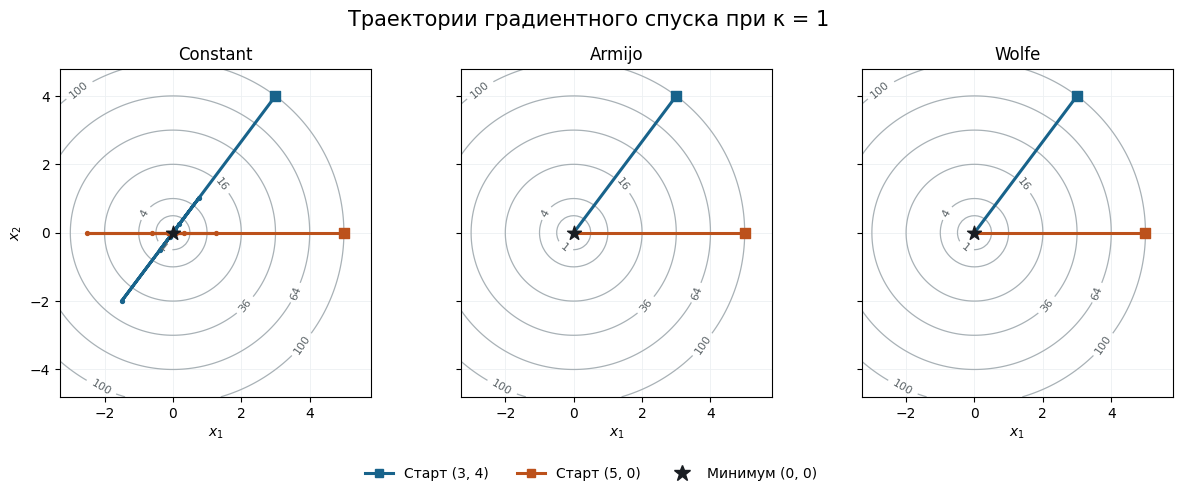

In [7]:
trajectory_figure(histories, 1)
plt.show()

Пояснение: При $\kappa=1$ линии уровня — окружности. Градиент равен $8x$, поэтому траектория из каждой точки лежит на прямой через центр. Армихо и Вульф подбирают шаг $1/8$ и сразу попадают в центр. При постоянном шаге $3/16$ новая точка равна $-x_k/2$. Метод каждый раз пересекает минимум и вдвое сокращает расстояние до него. Точки на линии отмечают эти переходы.

### Рисунок 2

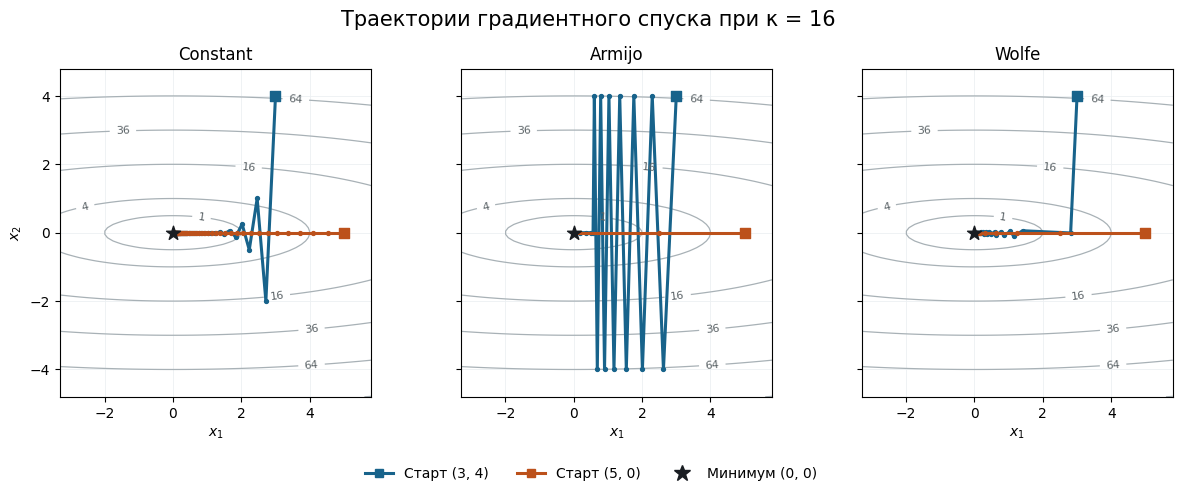

In [8]:
trajectory_figure(histories, 16)
plt.show()

Пояснение: При $\kappa=16$ линии уровня вытянуты вдоль $x_1$. Из точки $(3,4)$ особенно хорошо виден зигзаг Армихо. На первом шаге $\alpha=1/4$ точка переходит в $(2.625,-4)$: вторая координата меняет знак, а уменьшения первой хватает для принятия шага. Вульф на первом шаге оказывается вблизи оси $x_1$, затем продвигается к центру меньшими перемещениями. Из $(5,0)$ все три траектории идут по горизонтальной оси.

### Таблица числа обновлений

In [9]:
display(Markdown(steps_table(histories)))

| κ | Начальная точка | Constant | Armijo | Wolfe |
|---:|:---|---:|---:|---:|
| 1 | (3, 4) | 14 | 1 | 1 |
| 1 | (5, 0) | 14 | 1 | 1 |
| 16 | (3, 4) | 63 | 17 | 42 |
| 16 | (5, 0) | 94 | 2 | 14 |

 На данной таблице представлено число обновлений до выполнения критерия остановки. Все 12 запусков завершились со статусом success. Условия остановки задают одинаковое относительное уменьшение нормы градиента. Абсолютная точность по координатам может различаться.

### Дополнительный вопрос: Как отличается поведение метода в зависимости от числа обусловленности функции, выбора начальной точки и стратегии выбора шага?

**Как влияет обусловленность?** При $\kappa=1$ кривизна одинакова во всех направлениях. При $\kappa=16$ вдоль $x_2$ функция меняется в 16 раз круче, чем вдоль $x_1$. Из точки $(3,4)$ шаг, подходящий для крутой оси, даёт небольшой прогресс по пологой. На постоянном шаге число итераций выросло с 14 до 63, у Армихо — с 1 до 17, у Вульфа — с 1 до 42.

**Как влияет начальная точка?** При $\kappa=16$ из $(5,0)$ зигзагов нет. Армихо нужно 2 шага вместо 17, Вульфу — 14 вместо 42. У постоянного шага результат обратный: 94 шага вместо 63. По пологой оси координата за шаг умножается на $1-(3/16)\cdot0.5=29/32$. Кроме того, в $(5,0)$ начальная норма градиента меньше, поэтому относительный критерий требует меньшей конечной нормы. Одинаковое расстояние до минимума само по себе не определяет число итераций.

**Как влияет стратегия шага?** На второй функции в этих запусках меньше всего итераций потребовалось Армихо. Например, из $(5,0)$ первый принятый шаг равен 1, а второй равен 2 и точно приводит в минимум. Вульф в том же случае принимает шаг 1, который удовлетворяет обоим его условиям, и постепенно сокращает первую координату вдвое. По таблице можно сравнить число итераций. Для сравнения времени работы понадобилось бы также учесть затраты на поиск каждого шага.

## Задание 4. Эксперимент: число итераций градиентного спуска в зависимости от числа обусловленности и размерности
Я исследовал, как число шагов $T(n,\kappa)$ до сходимости зависит от размерности $n$ и числа обусловленности $\kappa$. Минимизируем квадратичную функцию
$$f(x)=\tfrac12 x^\top A x-b^\top x,\qquad \nabla f(x)=Ax-b.$$

Для каждой комбинации $n\in\{10,100,1000\}$ и $\kappa\in\{1,2,5,10,20,50,100,200\}$ я сгенерировал пять задач. Матрица $A$ - диагональная. Первый и последний элементы диагонали равны $1$ и $\kappa$, остальные независимо выбираются из равномерного распределения на $[1,\kappa]$. Поэтому отношение наибольшего собственного значения к наименьшему в точности равно заданному $\kappa$. Координаты $b$ независимо выбираются из стандартного нормального распределения. Для каждой задачи генерируем новую диагональ и новый вектор $b$. Матрицу храним в разреженном диагональном формате. Начальное значение генератора NumPy — 42.

Я использовал метод градиентного спуска из задания 2, начальную точку $x_0=0$ и правило постоянного шага $\alpha=1/\lambda_{\max}(A)=1/\kappa$. Шаг фиксирован внутри каждого запуска. Такая настройка учитывает кривизну функции и обеспечивает сходимость на всей сетке. Останавливал метод при $\|\nabla f(x_k)\|^2\leq 10^{-8}\|\nabla f(x_0)\|^2$, лимит — 3000 шагов. За одну итерацию считаю обновление точки. Начальная точка соответствует нулю итераций.

### Результаты

In [10]:
import numpy as np
from scipy.sparse import diags
from optimization import gradient_descent
from oracles import QuadraticOracle

dimensions = [10, 100, 1000]
kappas = [1, 2, 5, 10, 20, 50, 100, 200]
repeats = 5
tolerance = 1e-8
rng = np.random.default_rng(42)
counts = np.empty((len(dimensions), repeats, len(kappas)), dtype=int)

for i, n in enumerate(dimensions):
    for repeat in range(repeats):
        for j, kappa in enumerate(kappas):
            diagonal = rng.uniform(1, kappa, size=n)
            diagonal[0], diagonal[-1] = 1, kappa
            A = diags(diagonal, format="dia")
            b = rng.standard_normal(n)
            oracle = QuadraticOracle(A, b)
            point, status, history = gradient_descent(
                oracle, np.zeros(n), tolerance=tolerance, max_iter=3000,
                line_search_options={"method": "Constant", "c": 1 / kappa},
                trace=True,
            )
            if status != "success":
                raise RuntimeError(f"n={n}, κ={kappa}, повтор {repeat + 1}: {status}")
            counts[i, repeat, j] = len(history["grad_norm"]) - 1

print(f"Критерий остановки выполнен во всех {counts.size} запусках.")

Критерий остановки выполнен во всех 120 запусках.


Всего 120 запусков: три размерности, восемь значений числа обусловленности и пять повторов.

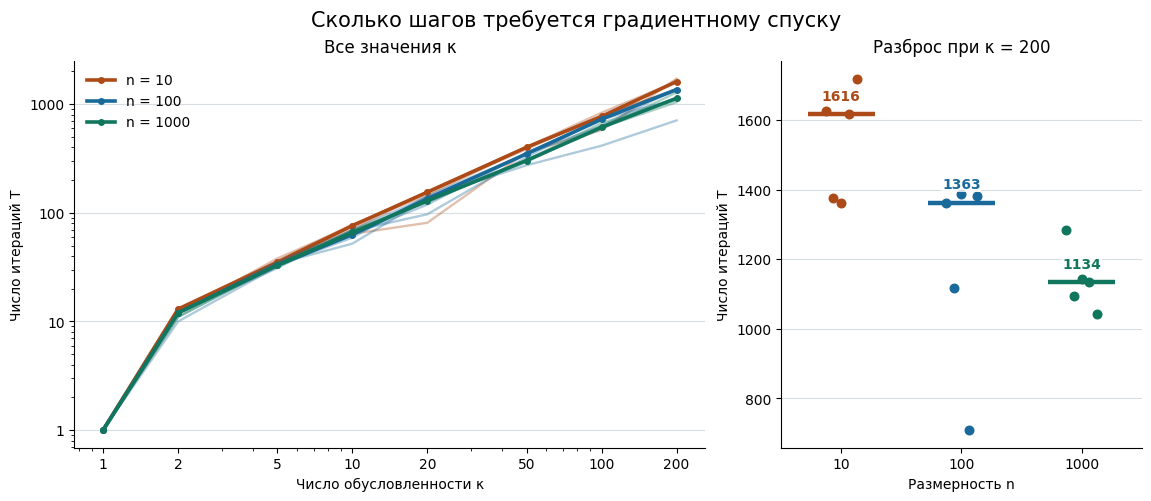

In [11]:
import matplotlib.pyplot as plt
from matplotlib.ticker import ScalarFormatter

colors = ["#ac4b18", "#19699a", "#11765e"]
fig, (ax, detail) = plt.subplots(
    1, 2, figsize=(11.4, 4.9), width_ratios=[1.75, 1], layout="constrained"
)
for i, (n, color) in enumerate(zip(dimensions, colors)):
    for series in counts[i]:
        ax.plot(kappas, series, color=color, linewidth=1.7, alpha=0.35)
    medians = np.median(counts[i], axis=0)
    ax.plot(kappas, medians, color=color, linewidth=2.6, marker="o",
            markersize=4, label=f"n = {n}")

    offsets = np.linspace(-0.13, 0.13, repeats)
    detail.scatter(i + offsets, counts[i, :, -1], s=38, color=color)
    detail.hlines(medians[-1], i - 0.28, i + 0.28, color=color, linewidth=3.2)
    detail.annotate(f"{int(medians[-1])}", (i, medians[-1]),
                    xytext=(0, 10), textcoords="offset points", ha="center",
                    color=color, fontsize=10, fontweight="bold",
                    bbox=dict(facecolor="white", edgecolor="none", alpha=0.8, pad=0.5))

ax.set(xscale="log", yscale="log", xlabel="Число обусловленности κ",
       ylabel="Число итераций T", title="Все значения κ")
ax.set_xticks(kappas, labels=[str(k) for k in kappas])
ax.set_yticks([1, 10, 100, 1000])
ax.yaxis.set_major_formatter(ScalarFormatter())
ax.legend(frameon=False, loc="upper left")
detail.set(xlabel="Размерность n", ylabel="Число итераций T",
           title=f"Разброс при κ = {kappas[-1]}", xlim=(-0.5, len(dimensions) - 0.5))
detail.set_xticks(range(len(dimensions)), labels=[str(n) for n in dimensions])
for panel in (ax, detail):
    panel.set_axisbelow(True)
    panel.grid(axis="y", color="#d9dde1", linewidth=0.8)
    panel.spines[["top", "right"]].set_visible(False)
fig.suptitle("Сколько шагов требуется градиентному спуску", fontsize=15)
plt.show()

Слева обе оси логарифмические. Каждый цвет соответствует одной размерности. Пять полупрозрачных кривых одного цвета показывают пять повторов эксперимента, жирная линия с маркерами соединяет их медианы. Чем выше число обусловленности, тем больше шагов требуется для всех трёх размерностей. Справа отдельно показаны те же результаты при $\kappa=200$ в линейном масштабе. Каждая точка — один запуск, горизонтальная черта — медиана. Семейства частично перекрываются: например, при $n=100$ число шагов меняется от 709 до 1387.

### Таблица средних чисел итераций по пяти запускам

In [12]:
import pandas as pd

table = pd.DataFrame(np.median(counts, axis=1).astype(int).T,
                     index=pd.Index(kappas, name="κ"),
                     columns=[f"n = {n}" for n in dimensions])
display(table)

,n = 10,n = 100,n = 1000
κ,,,
1,1,1,1
2,13,12,12
5,35,33,33
10,76,63,66
20,155,135,129
50,401,349,303
100,771,726,613
200,1616,1363,1134


### Пояснения

**Число обусловленности.** При $\kappa=1$ матрица $A$ единичная и $\alpha=1$. Из $x_0=0$ метод за один шаг переходит в $x_1=b$, точный минимум при любой размерности. Когда $\kappa$ возрастает, сходимость замедляется. Например, при $n=1000$ медиана составила 66 итераций для $\kappa=10$, 613 для $\kappa=100$ и 1134 для $\kappa=200$. На этом участке рост близок к пропорциональному.

Причину видно из формулы для градиента. По координате с диагональным элементом $a_i$ после одного шага получаем $g_{k+1,i}=(1-a_i/\kappa)\,g_{k,i}$. В самом пологом направлении $a_i=1$. При $\kappa=200$ за шаг остаётся $199/200$ предыдущей компоненты градиента, поэтому для достижения точности могут потребоваться сотни шагов.

**Размерность.** Увеличение $n$ в этой серии не привело к систематическому росту числа итераций. При $\kappa=200$ медианы для $n=10,100,1000$ составили 1616, 1363 и 1134 шага. При $\kappa=10$ порядок другой: 76, 63 и 66. Общая оценка $\|g_k\|\leq(1-1/\kappa)^k\|g_0\|$ напрямую зависит от $\kappa$. Фактический момент остановки зависит также от промежуточных собственных значений и от того, какая доля начального градиента приходится на медленные направления. При $x_0=0$ начальный градиент равен $-b$, поэтому разные случайные задачи дают разное число шагов даже при одинаковых $n$ и $\kappa$. По пяти повторам универсальную зависимость от $n$ установить нельзя. В эксперименте измерялось число итераций, время одной итерации не измерялось.

# Часть 3. Метод Ньютона
## Теоретическое введение

Метод Ньютона:
$$x_{k+1} = x_k - \alpha_k [\nabla^2 f(x_k)]^{-1} \nabla f(x_k).$$

Для метода Ньютона очень важно использовать единичный шаг $\alpha_k = 1$, чтобы обеспечить локальную квадратичную сходимость. Поэтому в алгоритмах линейного поиска нужно всегда первым делом пробовать единичный шаг. Теория гарантирует, что в зоне квадратичной сходимости метода Ньютона единичный шаг будет удовлетворять условиям Армихо/Вульфа и поэтому будет приниматься автоматически. Если единичный шаг не удовлетворяет условиям Армихо/Вульфа, то алгоритмы линейного поиска его уменьшат и тем самым обеспечат глобальную сходимость метода Ньютона.

Вычисление ньютоновского направления $d_k = -[\nabla^2 f(x_k)]^{-1} \nabla f(x_k)$ эквивалентно решению линейной системы уравнений
$$\nabla^2 f(x_k)\, d_k = -\nabla f(x_k).$$
Если гессиан — положительно определённая матрица ($\nabla^2 f(x_k) \succ 0$), то предпочтительным методом решения такой системы является разложение Холецкого: как и метод Гаусса, оно работает за $O(n^3)$, но является вычислительно более эффективным. Если матрица системы не является положительно определённой, то разложение Холецкого сможет обнаружить это и сообщить (бросить исключение).

### Выполнение задания части 3

## Задание 5. Метод Ньютона — файл `optimization.py`

Я реализовал функцию `newton` по аналогии с `gradient_descent` из задания 2 с необходимыми отличиями

Отрывок кода из файла `optimization.py` следующий:

In [ ]:
    start_time = datetime.now()

    for k in range(max_iter + 1):
        if not np.all(np.isfinite(x_k)):
            return x_k, 'computational_error', history

        value = oracle.func(x_k)
        grad = oracle.grad(x_k)
        if value is None or grad is None:
            return x_k, 'computational_error', history

        grad_norm = np.linalg.norm(grad)
        if not np.all(np.isfinite(value)) or not np.isfinite(grad_norm):
            return x_k, 'computational_error', history

        if k == 0:
            stop_norm = np.sqrt(tolerance) * grad_norm

        if trace:
            history['time'].append((datetime.now() - start_time).total_seconds())
            history['func'].append(value)
            history['grad_norm'].append(grad_norm)
            if x_k.size <= 2:
                history['x'].append(x_k.copy())

        if display:
            print(f'k = {k}, f = {value}, grad_norm = {grad_norm:.6g}')

        if grad_norm <= stop_norm:
            return x_k, 'success', history
        if k == max_iter:
            break

        # Вычисляем гессиан в текущей точке.
        hess = oracle.hess(x_k)
        if scipy.sparse.issparse(hess):
            hess = hess.toarray()
        if hess is None or not np.all(np.isfinite(hess)):
            return x_k, 'computational_error', history

        # Решаем систему H d = -grad через разложение Холецкого.
        try:
            factor = scipy.linalg.cho_factor(hess, lower=True, check_finite=False)
            direction = scipy.linalg.cho_solve(factor, -grad, check_finite=False)
        except LinAlgError:
            return x_k, 'newton_direction_error', history

        if not np.all(np.isfinite(direction)):
            return x_k, 'computational_error', history

        # На каждой итерации начинаем подбор шага с единицы.
        alpha = line_search_tool.line_search(oracle, x_k, direction, previous_alpha=1.0)
        if alpha is None or not np.isfinite(alpha):
            return x_k, 'computational_error', history

        x_k = x_k + alpha * direction

    return x_k, 'iterations_exceeded', history

### Проверка задания 5

In [14]:
!python -m pytest -q presubmit_tests.py::test_newton_basic presubmit_tests.py::test_newton_1d presubmit_tests.py::test_newton_fail

...                                                                      [100%]
3 passed in 0.50s


Я реализовал метод Ньютона и сделал проверку. На каждой итерации направление вычисляется из системы \(H_k d_k=-\nabla f(x_k)\) с помощью разложения Холецкого. Такой способ учитывает кривизну функции и позволяет обойтись без вычисления обратной матрицы. Подбор шага начинается с единицы. Метод завершает работу, когда квадрат нормы градиента достигает заданной доли от начального значения. Проверка пройдена успешно.

# Часть 4. Логистическая регрессия
## Теоретическое введение
## 4.1 Двухклассовая логистическая регрессия

Логистическая регрессия является стандартной моделью в задачах классификации. Для простоты рассмотрим лишь случай бинарной классификации. Неформально задача формулируется следующим образом. Имеется обучающая выборка $(a_i, b_i)_{i=1}^m$, состоящая из $m$ векторов $a_i \in \mathbb{R}^n$ (называемых признаками) и соответствующих им чисел $b_i \in \{-1, 1\}$ (называемых классами). Нужно построить алгоритм $b(\cdot)$, который для произвольного нового вектора признаков $a$ автоматически определит его класс $b(a) \in \{-1, 1\}$.

В модели логистической регрессии определение класса выполняется по знаку линейной комбинации компонент вектора $a$ с некоторыми фиксированными коэффициентами $x \in \mathbb{R}^n$:
$$b(a) := \mathrm{sign}(\langle a, x \rangle).$$

Коэффициенты $x$ являются параметрами модели и настраиваются с помощью решения следующей оптимизационной задачи:
$$\underset{x \in \mathbb{R}^n}{\min} \left( \frac{1}{m} \sum_{i=1}^m \ln(1 + \exp(-b_i \langle a_i, x \rangle)) + \frac{\lambda}{2} \|x\|_2^2 \right),$$
где $\lambda > 0$ — коэффициент регуляризации (параметр модели).

## 4.2 Разностная проверка градиента и гессиана

Проверить правильность реализации подсчёта градиента можно с помощью конечных разностей:
$$[\nabla f(x)]_i \approx \frac{f(x + \varepsilon_1 e_i) - f(x)}{\varepsilon_1},$$
где $e_i := (0, \ldots, 0, 1, 0, \ldots, 0)$ — $i$-й базисный орт, а $\varepsilon_1$ — достаточно маленькое положительное число: $\varepsilon_1 \sim \sqrt{\varepsilon_{mach}}$, где $\varepsilon_{mach}$ — машинная точность ($\approx 10^{-16}$ для типа `double`).

Вторые производные:
$$[\nabla^2 f(x)]_{ij} \approx \frac{f(x + \varepsilon_2 e_i + \varepsilon_2 e_j) - f(x + \varepsilon_2 e_i) - f(x + \varepsilon_2 e_j) + f(x)}{\varepsilon_2^2},$$
здесь $\varepsilon_2 \sim \sqrt[3]{\varepsilon_{mach}}$.

### Выполнение заданий части 4
## Задание 6. Формулы для функции, градиента и гессиана

Пусть $A\in\mathbb R^{m\times n}$ — матрица признаков, в которой каждая строка соответствует одному объекту, $b\in\{-1,1\}^m$ — вектор меток классов, а $x\in\mathbb R^n$ — вектор параметров модели. Обозначаю через $\odot$ поэлементное умножение, а через $\mathbf 1_m$ — вектор из $m$ единиц.

**1. Функция потерь.** Вектор $Ax$ содержит оценки модели для всех объектов. Умножаю их поэлементно на истинные метки и получаю вектор отступов $z=b\odot(Ax)$. Чем больше положительный отступ $z_i$, тем меньше потеря на этом объекте. При отрицательном отступе знак предсказания расходится с истинной меткой.

Для одного отступа логистическая потеря равна $\ell(t)=\ln(1+e^{-t})$. Применяю её поэлементно к $z$, усредняю результат с помощью $\mathbf 1_m^\top$ и добавляю регуляризацию с коэффициентом $\lambda>0$. Я получил:

$$
f(x)=\frac{1}{m}\mathbf 1_m^\top\ell(z)
+\frac{\lambda}{2}x^\top x,
\qquad z=b\odot(Ax).
$$

**2. Градиент.** Я ввёл $\sigma(t)=1/(1+e^{-t})$. Производная потери по одному отступу равна

$$
\ell'(t)=-\frac{e^{-t}}{1+e^{-t}}=-\sigma(-t).
$$

Далее я обозначаю $p=\sigma(-z)$. Для объекта $i$ отступ равен $z_i=b_i a_i^\top x$, поэтому его градиент по $x$ равен $b_i a_i$. По правилу цепочки вклад этого объекта в градиент потери равен $-p_i b_i a_i$. Матричное умножение на $A^\top$ объединяет вклады всех объектов, а производная регуляризатора даёт $\lambda x$. Итак,

$$
\nabla f(x)=-\frac{1}{m}A^\top(b\odot p)+\lambda x,
\qquad p=\sigma(-z).
$$

**3. Гессиан.** Продифференцирую потерю ещё раз. Поскольку $\sigma'(t)=\sigma(t)(1-\sigma(t))$, получается:

$$
\ell''(t)=\sigma(-t)\bigl(1-\sigma(-t)\bigr).
$$

Для всех объектов эти значения образуют вектор $s=p\odot(\mathbf 1_m-p)$. При повторном дифференцировании по $x$ метка класса входит в произведение дважды. Поскольку $b_i^2=1$, вклад объекта в матрицу вторых производных равен $s_i a_i a_i^\top$. В матричной форме гессиан имеет вид

$$
\nabla^2 f(x)=\frac{1}{m}A^\top\operatorname{Diag}(s)A+\lambda I_n,
\qquad s=p\odot(\mathbf 1_m-p).
$$

Здесь $\operatorname{Diag}(s)$ — диагональная матрица весов объектов. Все веса $s_i$ неотрицательны, поэтому первое слагаемое гессиана положительно полуопределено. Добавление $\lambda I_n$ при $\lambda>0$ делает гессиан положительно определённым. Именно это свойство позволяет вычислять направление Ньютона через разложение Холецкого, как в задании 5.

## Задание 7. Оракул логистической регрессии и проверка производных

Методы `func`, `grad` и `hess` класса `LogRegL2Oracle` вычисляют регуляризованную логистическую потерю, её градиент и гессиан по формулам задания 6. Для вычисления потери используется `np.logaddexp`, для сигмоиды — `expit`. При построении гессиана каждую строку матрицы признаков умножаем на соответствующий вес кривизны. При разреженном хранении исходная матрица остаётся разреженной, а метод возвращает гессиан в виде плотной матрицы.

Для проверки я сгенерировал 12 объектов с четырьмя признаками и метками из $\{-1,1\}$. Признаки берём из стандартного нормального распределения, затем каждый элемент с вероятностью 0.5 заменяем нулём. Устанавливаю `seed=42` и $\lambda=0.1$. Одни и те же данные храним как плотную матрицу и как разреженную матрицу CSR.

В нуле и двух случайных точках сравниваем аналитические производные с прямыми конечными разностями, рассчитанными только по значениям функции. Использую шаг $10^{-8}$ для градиента и $10^{-5}$ для гессиана. В таблице приведён максимум абсолютной разности по всем компонентам вектора или элементам матрицы.

In [16]:
import importlib
import oracles
importlib.reload(oracles)

<module 'oracles' from '/content/oracles.py'>

In [17]:
import numpy as np
from scipy.sparse import csr_matrix
from oracles import LogRegL2Oracle, grad_finite_diff, hess_finite_diff

rng = np.random.default_rng(42)
A = rng.normal(size=(12, 4))
A[rng.random(A.shape) < 0.5] = 0
b = rng.choice([-1, 1], size=12)
points = [np.zeros(4), rng.normal(size=4), rng.normal(size=4)]

print("Матрица   Точка   Ошибка градиента   Ошибка гессиана")
for name, matrix in [("dense", A), ("CSR", csr_matrix(A))]:
    oracle = LogRegL2Oracle(matrix, b, regcoef=0.1)
    for i, x in enumerate(points):
        grad_error = np.max(np.abs(oracle.grad(x) - grad_finite_diff(oracle.func, x)))
        hess_error = np.max(np.abs(oracle.hess(x) - hess_finite_diff(oracle.func, x)))
        print(f"{name:8}  {i:3}   {grad_error:16.2e}  {hess_error:16.2e}")
        assert grad_error < 1e-6 and hess_error < 1e-4


Матрица   Точка   Ошибка градиента   Ошибка гессиана
dense       0           1.03e-08          1.96e-06
dense       1           2.91e-08          4.58e-06
dense       2           7.55e-09          3.05e-06
CSR         0           1.03e-08          1.96e-06
CSR         1           2.91e-08          4.33e-06
CSR         2           2.36e-08          5.27e-06


### Проверка задания 7

In [20]:
!python -m pytest -q presubmit_tests.py::test_log_reg_usual presubmit_tests.py::test_grad_finite_diff_1 presubmit_tests.py::test_grad_finite_diff_2 presubmit_tests.py::test_hess_finite_diff_1 presubmit_tests.py::test_hess_finite_diff_2

.....                                                                    [100%]
5 passed in 0.48s


Для трёх пробных точек и обоих способов хранения данных наибольшее расхождение составило примерно $3.04\cdot10^{-8}$ для градиента и $5.27\cdot10^{-6}$ для гессиана. Разностная оценка гессиана чувствительнее к округлению: она использует разности близких значений функции и деление на квадрат малого шага. Во всех шести сравнениях ошибки уложились в выбранные допуски $10^{-6}$ и $10^{-4}$ соответственно.

## Итоговая проверка

In [19]:
!python -m pytest -q presubmit_tests.py

.............                                                            [100%]
13 passed in 0.47s


Все 13 предварительных тестов из `presubmit_tests.py` прошли успешно. Тесты проверяют выбор длины шага, работу градиентного спуска и метода Ньютона, вычисления квадратичного и логистического оракулов, а также разностные приближения градиента и гессиана. Во всех проверенных случаях реализации дали ожидаемые результаты.

# Вывод

В ходе выполнения данной работы я реализовал градиентный спуск и метод Ньютона, а также сравнил три способа выбора шага. На круговых линиях уровня правила Армихо и Вульфа привели метод в минимум за один шаг. На вытянутых линиях уровня траектория зависела от начальной точки. С ростом числа обусловленности требовалось больше итераций. Увеличение размерности такой закономерности не показало. Для метода Ньютона я вычислял направление с помощью разложения Холецкого. Для логистической регрессии я вывел формулы градиента и гессиана. Их проверка конечными разностями дала близкие результаты. Все 13 предварительных тестов прошли успешно.